In [1]:
import os
import collections
import random
import shutil
from pathlib import Path
import seaborn as sns
import sklearn
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix
print('The scikit-learn version is {}.'.format(sklearn.__version__))

from sklearn.metrics import multilabel_confusion_matrix, ConfusionMatrixDisplay
import numpy as np
import pandas as pd
from shutil import copy2 
import joblib
import json
from collections import Counter
import matplotlib.pyplot as plt

#for text pre-processing
import re, string
import nltk
nltk.download('stopwords')
nltk.download('omw-1.4')
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import SnowballStemmer
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('wordnet')
#model
#feature extraction
from sklearn.feature_extraction.text import TfidfVectorizer


/home/javi/.local/lib/python3.8/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.23.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


The scikit-learn version is 1.0.2.


[nltk_data] Downloading package stopwords to /home/javi/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /home/javi/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to /home/javi/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /home/javi/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package wordnet to /home/javi/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [2]:


##INPUT FILES HERE ##

#test_set 
test_set = [os.path.join("classifier-dataset/dataset/test_set", f) for f in os.listdir("classifier-dataset/dataset/test_set")]

test_set = random.sample(test_set, len(test_set))

print("Test Set: " + str(len(test_set)))


Test Set: 1250


In [3]:
#making labels, read the category from the name of the file 
def make_labels(data):
    files = data
    file_list = []
    train_labels = [None] * (len(files))
    count = 0
    docID = 0
    for fil in files:
        file_list.append(fil)
        train_labels[docID] = 'non-relevant'
        filepathTokens = fil.split('/')
        lastToken = filepathTokens[len(filepathTokens) - 1]
        if fil.endswith("_clinical.txt"):
            train_labels[docID] = 'clinical'
            count = count + 1
        elif fil.endswith("_non-clinical.txt"):
            train_labels[docID] = 'non-clinical'
            count = count + 1
        docID = docID + 1
    combined_labels_files = dict(zip(train_labels, file_list))
    #print (train_labels)
    #print (file_list)
    print (combined_labels_files)
    return train_labels, file_list, combined_labels_files
    

#make labels for multiclass test set

test_set_labels, test_file_list, combined_testing  = make_labels(test_set)

df_test = pd.DataFrame(data={'files': test_set, 'target':test_set_labels})


{'non-relevant': 'classifier-dataset/dataset/test_set/27864324_background.txt', 'clinical': 'classifier-dataset/dataset/test_set/24362413_clinical.txt', 'non-clinical': 'classifier-dataset/dataset/test_set/22576851_non-clinical.txt'}


Counter({'non-relevant': 641, 'non-clinical': 361, 'clinical': 248})
OrderedDict([('clinical', 248), ('non-clinical', 361), ('non-relevant', 641)])
[248, 361, 641]


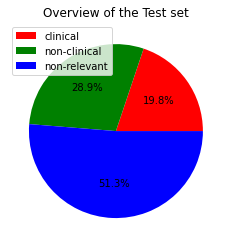

In [5]:
# to represent the distribution of the test:


labels = ['clinical','non-clinical','non-relevant']

sizes = Counter(test_set_labels)
print (sizes)
sizes = collections.OrderedDict(sorted(sizes.items()))
print (sizes)
sizes = list((sizes).values())
print (sizes)
colours = {'non-relevant':'b','non-clinical':'g','clinical':'r'}
plt.pie(sizes,colors=[colours[key] for key in labels],autopct='%1.1f%%')
plt.legend(labels)
plt.title('Overview of the Test set')
plt.show()

In [4]:
#convert to lowercase, strip and remove punctuations
def preprocess(text):
    text = text.lower() 
    text=text.strip()  
    text=re.compile('<.*?>').sub('', text) 
    text = re.compile('[%s]' % re.escape(string.punctuation)).sub(' ', text)  
    text = re.sub('\s+', ' ', text)  
    text = re.sub(r'\[[0-9]*\]',' ',text) 
    text=re.sub(r'[^\w\s]', '', str(text).lower().strip())
    text = re.sub(r'\d',' ',text) 
    text = re.sub(r'\s+',' ',text) 
    return text
 
# STOPWORD REMOVAL
def stopword(string):
    a= [i for i in string.split() if i not in stopwords.words('english')]
    return ' '.join(a)#LEMMATIZATION
# Initialize the lemmatizer
wl = WordNetLemmatizer()
 
# This is a helper function to map NTLK position tags
def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    else:
        return wordnet.NOUN# Tokenize the sentence

def lemmatizer(string):
    word_pos_tags = nltk.pos_tag(word_tokenize(string)) # Get position tags
    #a=[wl.lemmatize(tag[0], get_wordnet_pos(tag[1])) for idx, tag in enumerate(word_pos_tags)] # Map the position tag and lemmatize the word/token
    a=[wl.lemmatize(tag[0], get_wordnet_pos(tag[1])) + '_' + get_wordnet_pos(tag[1]) for idx, tag in enumerate(word_pos_tags)] # Map the position tag and lemmatize the word/token
    #a=[wl.lemmatize(tag[0], get_wordnet_pos(tag[1])) + '_' + tag[1] for idx, tag in enumerate(word_pos_tags)] # Map the position tag and lemmatize the word/token
    return " ".join(a)

def finalpreprocess(string):
    return lemmatizer(stopword(preprocess(string)))
    #return lemmatizer(preprocess(string))

In [5]:
#load text of files 
X_test = [Path(file).read_text() for file in test_set]


In [6]:
#preprocessing
X_test_preprocessed = [finalpreprocess(string) for string in X_test]
df_test[ 'text_preprocessed']=X_test_preprocessed 

In [7]:
#load trained model
debbie_model = joblib.load('debbie_model.pkl')
#load trained vectorizer
debbie_vectorizer = joblib.load('debbie_vectorizer.pkl')

In [8]:
#vectorization 
X_test_vectors_tfidf = debbie_vectorizer.transform(X_test_preprocessed)
#run model
y_predict = debbie_model.predict(X_test_vectors_tfidf)

In [9]:

print("Bag-of-Words (with Tf-Idf ) with SGDClassifier Logistic Regression")
print(classification_report(test_set_labels,y_predict))
print('Confusion Matrix:',confusion_matrix(test_set_labels, y_predict))
 

Bag-of-Words (with Tf-Idf ) with SGDClassifier Logistic Regression
              precision    recall  f1-score   support

    clinical       0.70      0.89      0.79       248
non-clinical       0.96      0.94      0.95       361
non-relevant       0.93      0.85      0.89       641

    accuracy                           0.88      1250
   macro avg       0.87      0.89      0.88      1250
weighted avg       0.90      0.88      0.89      1250

Confusion Matrix: [[221   6  21]
 [  2 341  18]
 [ 92   7 542]]


<AxesSubplot:>

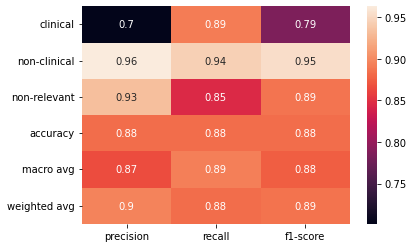

In [16]:
clf_report = classification_report(test_set_labels,y_predict,output_dict=True)
sns.heatmap(pd.DataFrame(clf_report).iloc[:-1, :].T, annot=True)

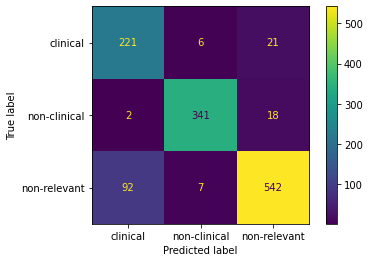

In [11]:
cm = confusion_matrix(test_set_labels, y_predict, labels=debbie_model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=debbie_model.classes_)

disp.plot()
